<a href="https://colab.research.google.com/github/MDiCapua/LLM_test/blob/main/EMO_vs_StdMoE_GSM8K_inferenza_4bit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EMO vs MoE standard: restrizione degli esperti valutata su GSM8K (solo inferenza, quantizzato a 4-bit)

Questo notebook carica i due checkpoint rilasciati, **`allenai/Emo_1b14b_1T`** e **`allenai/StdMoE_1b14b_1T`** (stessa architettura, cambia solo l'obiettivo di training), e li usa solo in inferenza, quantizzati a 4-bit, su una GPU T4 di Colab.

Per ogni modello:

1. misura la perplexity sulle soluzioni di GSM8K con tutti gli esperti;
2. sceglie un sottoinsieme di esperti per layer (25% e 12.5%: 32 e 16 esperti su 128) in due modi: router (gli esperti con la probabilità media di routing più alta su un piccolo set di calibrazione di GSM8K) e random (per un controllo sul reale funzionamento del routing);
3. restringe il modello a quel sottoinsieme mascherando i logit del router e rimisura la perplexity.

Per EMO la perplexity con il sottoinsieme scelto dal router dovrebbe crescere poco; per la MoE standard dovrebbe crescere molto di più; e per entrambi il sottoinsieme casuale dovrebbe andare peggio di quello scelto dal router.

**Criticità**
- Misura la perplexity, non l'accuracy di GSM8K: non riproduce il numero del paper. Nello specifico viene valutato il rapporto tra perplexity "ristretta" e perplexity "completa".
- I modelli sono quantizzati a 4-bit: i valori assoluti non coincidono con quelli in BF16.
- La selezione è one-shot, non la selezione greedy layerwise del repo.
- Pochi esempi (40 per scegliere gli esperti e 80 per il test): i numeri sono indicativi.

**Risorse richieste** Runtime GPU T4. Ogni modello è un download di circa 54 GB e richiede circa 70 GB di disco libero; dopo la valutazione i suoi file vengono cancellati dalla cache.

## 1. Controllo delle risorse e installazione

In [1]:
import subprocess, shutil, os
from pathlib import Path
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

import torch

print("GPU disponibile:", torch.cuda.is_available())
if torch.cuda.is_available():
    p = torch.cuda.get_device_properties(0)
    print(f"GPU: {p.name}, {p.total_memory/1e9:.1f} GB")
try:
    import psutil
    print(f"RAM: {psutil.virtual_memory().total/1e9:.0f} GB")
except Exception:
    pass
hf_cache = Path(os.environ.get("HF_HOME", Path.home() / ".cache" / "huggingface"))
hf_cache.mkdir(parents=True, exist_ok=True)
print(f"Disco libero dove si scaricano i modelli: {shutil.disk_usage(hf_cache).free/1e9:.0f} GB (servono circa 70)")

GPU disponibile: True
GPU: Tesla T4, 15.6 GB
RAM: 14 GB
Disco libero dove si scaricano i modelli: 66 GB (servono circa 70)


In [2]:
# transformers va tenuto a 4.57.1: il codice custom di EMO non funziona con la 5.x.
!pip install -q "transformers==4.57.1" "accelerate" "bitsandbytes>=0.46.1" datasets
import transformers, bitsandbytes
print("transformers:", transformers.__version__, "| bitsandbytes:", bitsandbytes.__version__)
assert transformers.__version__ == "4.57.1", "Riavvia il runtime e riesegui l'installazione."

transformers: 4.57.1 | bitsandbytes: 0.50.2


## 2. Configurazione

In [3]:
EMO_ID = "allenai/Emo_1b14b_1T"
STD_ID = "allenai/StdMoE_1b14b_1T"

RUN_EMO = True          # False per saltare un modello (ognuno costa circa 54 GB di download)
RUN_STD = True

N_PROFILE = 40          # problemi GSM8K (train) usati per scegliere gli esperti
N_TEST = 80             # problemi GSM8K (test) su cui si misura la perplexity
BUDGETS = [32, 16]      # esperti tenuti per layer (condiviso incluso): 25% e 12.5% di 128
RANDOM_SEEDS = [0, 1]   # sottoinsiemi casuali di controllo (si fa la media)
MAX_LEN = 384           # token massimi per esempio
BATCH_SIZE = 4

RESULTS_PATH = "/content/emo_gsm8k_results.json"

## 3. Funzioni di base

Le funzioni qui sotto fanno quattro cose: **profilare** il router (probabilità media di ogni esperto), **scegliere** il sottoinsieme, **restringere** il modello (maschera sui logit del router: un `-inf` fa sparire l'esperto e il softmax si rinormalizza sugli altri, come se fosse stato cancellato) e **misurare la perplexity** sulla sola parte di risposta di ogni problema.

In [4]:
import gc, json, math, re, time
from contextlib import contextmanager
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F


def moe_blocks(model):
    """Lista (indice layer, blocco MoE) dei layer che hanno un router (i layer densi si saltano)."""
    blocks = []
    for i, layer in enumerate(model.model.layers):
        if hasattr(layer.mlp, "gate"):
            if getattr(layer.mlp, "always_active_experts", None):
                raise NotImplementedError("always_active_experts non gestito da questo notebook")
            blocks.append((i, layer.mlp))
    return blocks


def build_examples(tok, rows, max_len):
    """Ogni esempio = (lista di token, lunghezza del prompt). La perdita si calcola solo sulla risposta."""
    out = []
    for r in rows:
        prompt = f"Question: {r['question']}\nAnswer:"
        answer = " " + re.sub(r"<<.*?>>", "", r["answer"])        # tolgo le annotazioni del calcolatore
        p = tok(prompt, add_special_tokens=False).input_ids
        a = tok(answer, add_special_tokens=False).input_ids
        ids = (p + a)[:max_len]
        if len(p) < len(ids):                                        # serve almeno 1 token di risposta
            out.append((ids, len(p)))
    return out


def make_batches(examples, bs, pad_id):
    order = sorted(range(len(examples)), key=lambda i: len(examples[i][0]))   # meno padding
    for s in range(0, len(order), bs):
        idx = order[s:s + bs]
        L = max(len(examples[i][0]) for i in idx)
        ids = torch.full((len(idx), L), pad_id, dtype=torch.long)
        att = torch.zeros((len(idx), L), dtype=torch.long)
        ans = torch.zeros((len(idx), L), dtype=torch.bool)          # True sui token di risposta
        for r, i in enumerate(idx):
            x, pl = examples[i]
            ids[r, :len(x)] = torch.tensor(x)
            att[r, :len(x)] = 1
            ans[r, pl:len(x)] = True
        yield ids, att, ans


@torch.no_grad()
def profile_router(model, examples, bs, pad_id):
    """Probabilita' media di routing di ogni esperto instradabile, per layer (token di padding esclusi)."""
    blocks = moe_blocks(model)
    sums = {i: torch.zeros(b.num_experts - b.num_shared_experts, dtype=torch.float64) for i, b in blocks}
    state = {}
    def make_hook(i, b):
        R = b.num_experts - b.num_shared_experts
        def hook(module, args, out):
            p = torch.softmax(out.detach().float()[:, :R], dim=-1)   # softmax solo sugli esperti instradabili
            m = state["mask"].to(p.device)
            sums[i] += p[m].sum(0).double().cpu()
        return hook
    handles = [b.gate.register_forward_hook(make_hook(i, b)) for i, b in blocks]
    n_tok, dev = 0, model.device
    try:
        for ids, att, ans in make_batches(examples, bs, pad_id):
            state["mask"] = att.reshape(-1).bool()
            model(input_ids=ids.to(dev), attention_mask=att.to(dev), use_cache=False)
            n_tok += int(att.sum())
    finally:
        for h in handles:
            h.remove()
    return {i: sums[i] / n_tok for i in sums}


def select_masks(mean_probs, blocks, m, mode, seed=0):
    """Maschera booleana per layer: True = esperto tenuto. L'esperto condiviso si tiene sempre e conta in m."""
    rng = np.random.default_rng(seed)
    masks = {}
    for i, b in blocks:
        E, S = b.num_experts, b.num_shared_experts
        R = E - S
        k = min(m - S, R)
        if mode == "router":
            keep = torch.topk(mean_probs[i], k).indices.tolist()
        elif mode == "random":
            keep = rng.choice(R, size=k, replace=False).tolist()
        else:
            raise ValueError(mode)
        mask = torch.zeros(E, dtype=torch.bool)
        mask[keep] = True
        mask[R:] = True                                              # esperti condivisi
        masks[i] = mask
    return masks


@contextmanager
def restrict_experts(model, masks):
    """Mentre il blocco e' attivo, gli esperti esclusi hanno logit -inf nel router."""
    handles = []
    for i, b in moe_blocks(model):
        def hook(module, args, out, mk=masks[i]):
            return out.masked_fill(~mk.to(out.device), float("-inf"))
        handles.append(b.gate.register_forward_hook(hook))
    try:
        yield
    finally:
        for h in handles:
            h.remove()


@torch.no_grad()
def perplexity(model, examples, bs, pad_id):
    """Perplexity sui soli token di risposta."""
    total_nll, total_tok, dev = 0.0, 0, model.device
    for ids, att, ans in make_batches(examples, bs, pad_id):
        logits = model(input_ids=ids.to(dev), attention_mask=att.to(dev), use_cache=False).logits[:, :-1].float()
        tgt = ids[:, 1:].to(dev)
        m = ans[:, 1:].to(dev)
        nll = F.cross_entropy(logits.reshape(-1, logits.size(-1)), tgt.reshape(-1), reduction="none").reshape(tgt.shape)
        total_nll += (nll * m).sum().item()
        total_tok += int(m.sum())
        del logits, nll
    return math.exp(total_nll / total_tok)


def free_gpu():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

## 4. Test rapido su un modello giocattolo

Prima di scaricare 54 GB, controllo che profilazione, selezione e restrizione funzionino su un EMO piccolo con pesi casuali. Scarica solo la configurazione e il codice del modello.

In [5]:
from transformers import AutoConfig, AutoModelForCausalLM

cfg = AutoConfig.from_pretrained(EMO_ID, trust_remote_code=True)
cfg.hidden_size, cfg.intermediate_size = 64, 64
cfg.num_hidden_layers, cfg.num_attention_heads, cfg.num_key_value_heads = 3, 4, 4
cfg.num_experts, cfg.num_shared_experts, cfg.num_experts_per_tok = 16, 1, 4
cfg.num_experts_per_layer = None
cfg.num_shared_experts_per_layer = None
cfg.always_active_experts = None
cfg.always_active_experts_per_layer = None
cfg.vocab_size, cfg.pad_token_id, cfg.eos_token_id, cfg.bos_token_id = 500, 0, 1, None
torch.manual_seed(0)
toy = AutoModelForCausalLM.from_config(cfg, trust_remote_code=True).eval()

rng = np.random.default_rng(0)
def fake(n):
    out = []
    for _ in range(n):
        L = int(rng.integers(12, 30))
        out.append((rng.integers(2, 500, size=L).tolist(), int(rng.integers(3, 8))))
    return out
ex_prof, ex_test = fake(8), fake(8)

blocks = moe_blocks(toy)
assert len(blocks) == 3, f"layer MoE trovati: {len(blocks)}"
probs = profile_router(toy, ex_prof, bs=4, pad_id=0)
for i, b in blocks:
    assert abs(float(probs[i].sum()) - 1.0) < 1e-4, "le probabilita' medie devono sommare a 1"

full = perplexity(toy, ex_test, 4, 0)
masks = select_masks(probs, blocks, m=6, mode="router")
with restrict_experts(toy, masks):
    restricted = perplexity(toy, ex_test, 4, 0)
    # dentro la restrizione, gli esperti esclusi devono avere probabilita' esattamente 0
    probs_r = profile_router(toy, ex_prof, bs=4, pad_id=0)
for i, b in blocks:
    R = b.num_experts - b.num_shared_experts
    excluded = ~masks[i][:R]
    assert float(probs_r[i][excluded].sum()) == 0.0, "un esperto escluso riceve ancora probabilita'"
    assert int(masks[i].sum()) == 6, "numero di esperti tenuti sbagliato"
rand_masks = select_masks(probs, blocks, m=6, mode="random", seed=0)
assert any((rand_masks[i] != masks[i]).any() for i in masks), "random e router non dovrebbero coincidere"
print(f"OK. Perplexity giocattolo: completo {full:.1f}, ristretto {restricted:.1f}")
del toy; free_gpu()

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


OK. Perplexity giocattolo: completo 511.8, ristretto 512.4


## 5. Dati: GSM8K

In [6]:
from datasets import load_dataset
gsm = load_dataset("openai/gsm8k", "main")
gsm_train = [gsm["train"][i] for i in range(N_PROFILE)]
gsm_test = [gsm["test"][i] for i in range(N_TEST)]
print(len(gsm_train), "problemi per la calibrazione,", len(gsm_test), "per il test")
print("Esempio:\n", gsm_test[0]["question"], "\n->", gsm_test[0]["answer"][:200])

40 problemi per la calibrazione, 80 per il test
Esempio:
 Janet’s ducks lay 16 eggs per day. She eats three for breakfast every morning and bakes muffins for her friends every day with four. She sells the remainder at the farmers' market daily for $2 per fresh duck egg. How much in dollars does she make every day at the farmers' market? 
-> Janet sells 16 - 3 - 4 = <<16-3-4=9>>9 duck eggs a day.
She makes 9 * 2 = $<<9*2=18>>18 every day at the farmer’s market.
#### 18


## 6. Valutazione dei due modelli

Per ogni modello: download, caricamento a 4-bit (esperti e attenzione in NF4, router e layer di output in FP32, calcolo in FP32 perché i modelli sono stati addestrati in bfloat16, che la T4 non ha), misure, poi cancellazione dei file dalla cache. I risultati di ogni modello vengono salvati su disco: se il runtime si interrompe, rieseguendo la cella i modelli già completati si possono saltare.

In [7]:
!nvidia-smi --query-gpu=memory.used,memory.total --format=csv #controllo che la GPU sia vuota

memory.used [MiB], memory.total [MiB]
3 MiB, 15360 MiB


In [8]:
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
import bitsandbytes as bnb


def load_4bit(repo_id):
    quant = BitsAndBytesConfig(
        load_in_4bit=True, bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.float32,
        llm_int8_skip_modules=["gate", "lm_head"],      # router e output restano in FP32
    )
    model = AutoModelForCausalLM.from_pretrained(
        repo_id, trust_remote_code=True, quantization_config=quant,
        torch_dtype=torch.float32, device_map={"": 0}, low_cpu_mem_usage=True,
    ).eval()
    tok = AutoTokenizer.from_pretrained(repo_id, trust_remote_code=True)
    return model, tok


def delete_from_hf_cache(repo_id):
    from huggingface_hub import scan_cache_dir
    cache = scan_cache_dir()
    for repo in cache.repos:
        if repo.repo_id == repo_id:
            cache.delete_revisions(*[r.commit_hash for r in repo.revisions]).execute()
            print(f"Cancellato {repo_id} dalla cache ({repo.size_on_disk/1e9:.0f} GB liberati)")


def evaluate_model(label, repo_id):
    t0 = time.time()
    model, tok = load_4bit(repo_id)
    blocks = moe_blocks(model)
    mem = torch.cuda.memory_allocated() / 1e9
    n4 = sum(isinstance(m, bnb.nn.Linear4bit) for m in model.modules())
    gate_fp32 = all(b.gate.weight.dtype == torch.float32 and not isinstance(b.gate, bnb.nn.Linear4bit) for _, b in blocks)
    print(f"{label}: caricato in {(time.time()-t0)/60:.1f} min | {len(blocks)} layer MoE, "
          f"{blocks[0][1].num_experts} esperti per layer ({blocks[0][1].num_shared_experts} condiviso) | "
          f"{n4} linear a 4-bit | GPU {mem:.1f} GB | router in FP32: {gate_fp32}")
    if not gate_fp32:
        raise RuntimeError("I router non sono in FP32: la restrizione sarebbe inaffidabile.")
    if mem > 12:
        print("ATTENZIONE: memoria GPU molto alta, gli esperti potrebbero non essere quantizzati.")

    pad_id = tok.pad_token_id if tok.pad_token_id is not None else (tok.eos_token_id or 0)
    prof_ex = build_examples(tok, gsm_train, MAX_LEN)
    test_ex = build_examples(tok, gsm_test, MAX_LEN)
    print(f"   esempi: {len(prof_ex)} calibrazione, {len(test_ex)} test")

    rows = []
    ppl_full = perplexity(model, test_ex, BATCH_SIZE, pad_id)
    rows.append(dict(model=label, condition="completo", m=128, ppl=ppl_full))
    print(f"   completo: perplexity {ppl_full:.2f}")

    probs = profile_router(model, prof_ex, BATCH_SIZE, pad_id)
    for m in BUDGETS:
        masks = select_masks(probs, blocks, m, "router")
        with restrict_experts(model, masks):
            p = perplexity(model, test_ex, BATCH_SIZE, pad_id)
        rows.append(dict(model=label, condition="router", m=m, ppl=p))
        rnd = []
        for s in RANDOM_SEEDS:
            masks = select_masks(probs, blocks, m, "random", seed=s)
            with restrict_experts(model, masks):
                rnd.append(perplexity(model, test_ex, BATCH_SIZE, pad_id))
        rows.append(dict(model=label, condition="random", m=m, ppl=float(np.mean(rnd))))
        print(f"   m={m}: router {p:.2f} | random {np.mean(rnd):.2f}")

    print(f"{label}: finito in {(time.time()-t0)/60:.1f} min")
    del model, tok
    free_gpu()
    delete_from_hf_cache(repo_id)
    return rows


results = json.load(open(RESULTS_PATH)) if os.path.exists(RESULTS_PATH) else {}
for label, repo_id, flag in [("EMO", EMO_ID, RUN_EMO), ("StdMoE", STD_ID, RUN_STD)]:
    if not flag:
        continue
    if label in results:
        print(f"{label}: risultati gia' presenti in {RESULTS_PATH}, salto.")
        continue
    results[label] = evaluate_model(label, repo_id)
    json.dump(results, open(RESULTS_PATH, "w"))

`torch_dtype` is deprecated! Use `dtype` instead!


Loading checkpoint shards:   0%|          | 0/11 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/69.0 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/207 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/196 [00:00<?, ?B/s]

EMO: caricato in 3.9 min | 16 layer MoE, 128 esperti per layer (1 condiviso) | 6208 linear a 4-bit | GPU 9.1 GB | router in FP32: True
   esempi: 40 calibrazione, 80 test
   completo: perplexity 4.03
   m=32: router 3.97 | random 8.99
   m=16: router 3.87 | random 13.69
EMO: finito in 7.3 min
Cancellato allenai/Emo_1b14b_1T dalla cache (54 GB liberati)
StdMoE: risultati gia' presenti in /content/emo_gsm8k_results.json, salto.


## 7. Risultati

Perplexity su GSM8K (solo risposte):
condition   completo  router  random
model  m                            
StdMoE 128      3.64     NaN     NaN
       32        NaN    5.58   36.34
       16        NaN   12.03  542.83
EMO    128      4.03     NaN     NaN
       32        NaN    3.97    8.99
       16        NaN    3.87   13.69

Rapporto rispetto al modello completo (1.0 = nessun peggioramento):
condition  router  random
model  m                 
StdMoE 32    1.53    9.99
       16    3.31  149.15
EMO    32    0.98    2.23
       16    0.96    3.40


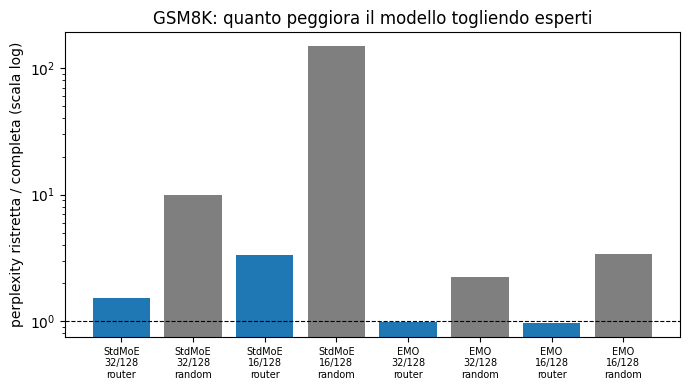

In [9]:
import matplotlib.pyplot as plt

df = pd.DataFrame([r for rows in results.values() for r in rows])
base = df[df.condition == "completo"].set_index("model")["ppl"]
df["rapporto"] = df.apply(lambda r: r.ppl / base[r.model], axis=1)

print("Perplexity su GSM8K (solo risposte):")
print(df.pivot_table(index=["model", "m"], columns="condition", values="ppl", sort=False).round(2).to_string())
print("\nRapporto rispetto al modello completo (1.0 = nessun peggioramento):")
tab = df[df.condition != "completo"].pivot_table(index=["model", "m"], columns="condition", values="rapporto", sort=False).round(2)
print(tab.to_string())

fig, ax = plt.subplots(figsize=(7, 4))
labels, vals, colors = [], [], []
for model in df.model.unique():
    for m in BUDGETS:
        for cond, col in [("router", "tab:blue"), ("random", "tab:gray")]:
            r = df[(df.model == model) & (df.m == m) & (df.condition == cond)]
            if len(r):
                labels.append(f"{model}\n{m}/128\n{cond}")
                vals.append(float(r.rapporto.iloc[0]))
                colors.append(col)
ax.bar(range(len(vals)), vals, color=colors)
ax.set_xticks(range(len(vals)))
ax.set_xticklabels(labels, fontsize=7)
ax.set_yscale("log")
ax.axhline(1.0, color="k", lw=0.8, ls="--")
ax.set_ylabel("perplexity ristretta / completa (scala log)")
ax.set_title("GSM8K: quanto peggiora il modello togliendo esperti")
plt.tight_layout()
plt.show()

## 8. Conclusioni

- **Rapporto vicino a 1** = restringere il modello non ne degrada le prestazioni. Per confermare il paper questo dovrebbe essere il caso di EMO con il sottoinsieme scelto dal router, mentre la MoE standard dovrebbe allontanarsi di più dall'1.
- **router contro random**: se la scelta del ruter non fosse migliore di quella casuale, la selezione non starebbe catturando nulla di specifico per GSM8K.
- **Criticità**: in questo notebook si considera la perplexity e non accuracy; si valutano modelli a 4-bit e non BF16; la selezione è one-shot e non layerwise; per velocità uso soli 40 problemi di calibrazione e 80 di test.